# Lab Mid Exam: HOG vs SIFT on Blood-Cell Images
**Name:** Talal Ahmed Tarar  
**Registration Number:** FA23-BAI-031  

### Personal Settings (Derived from Registration Number `031`)
| Setting | Rule | My Value |
| :--- | :--- | :--- |
| **Random seed** | Last two digits of registration number (`031`) | **`31`** |
| **HOG cell size** | Last digit odd (`1`) $\rightarrow 16 \times 16$ | **`16 x 16`** |
| **SIFT grid size** | Last digit `0` to `4` (`1`) $\rightarrow 4 \times 4$ grid (16 keypoints) | **`4 x 4` (16 keypoints)** |

In [1]:
import os
import zipfile
import glob
import random
import numpy as np
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from skimage.feature import hog
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
from google.colab import drive
import warnings
warnings.filterwarnings('ignore')

# ==========================================
# PERSONAL SETTINGS (Reg No: 031)
# ==========================================
SEED = 31
HOG_CELL_SIZE = (16, 16)
SIFT_GRID_SIZE = (4, 4) # 16 keypoints

# Fixed Settings for Everyone
IMG_SIZE = (128, 128)
HOG_ORIENTATIONS = 9
HOG_CELLS_PER_BLOCK = (2, 2)
C_VALUES = [0.1, 1, 10]
ROTATION_ANGLE = 20
NOISE_SIGMA = 0.05

# Lock all random seeds for 100% reproducibility
random.seed(SEED)
np.random.seed(SEED)

# Mount Google Drive
drive.mount('/content/drive')

Mounted at /content/drive


---
## Q1. Data Setup (3 Marks)
Loading the `BloodMNIST` dataset from Google Drive, filtering the four target classes (`eosinophil (1)`, `monocyte (5)`, `neutrophil (6)`, `platelet (7)`), converting to grayscale, resizing to $128 \times 128$, and sampling 100 train, 30 validation, and 30 test images per class using `SEED = 31`.

Found dataset archive at: /content/drive/MyDrive/Intro to CV/BloodMNIST.zip
Dataset extracted successfully.
Data root directory: /content/BloodMNIST_data

=== SPLIT SHAPES AND CLASS COUNTS ===
Train      | Shape: (400, 128, 128)  | Counts: {'eosinophil (1)': 100, 'monocyte (5)': 100, 'neutrophil (6)': 100, 'platelet (7)': 100}
Validation | Shape: (120, 128, 128)  | Counts: {'eosinophil (1)': 30, 'monocyte (5)': 30, 'neutrophil (6)': 30, 'platelet (7)': 30}
Test       | Shape: (120, 128, 128)  | Counts: {'eosinophil (1)': 30, 'monocyte (5)': 30, 'neutrophil (6)': 30, 'platelet (7)': 30}


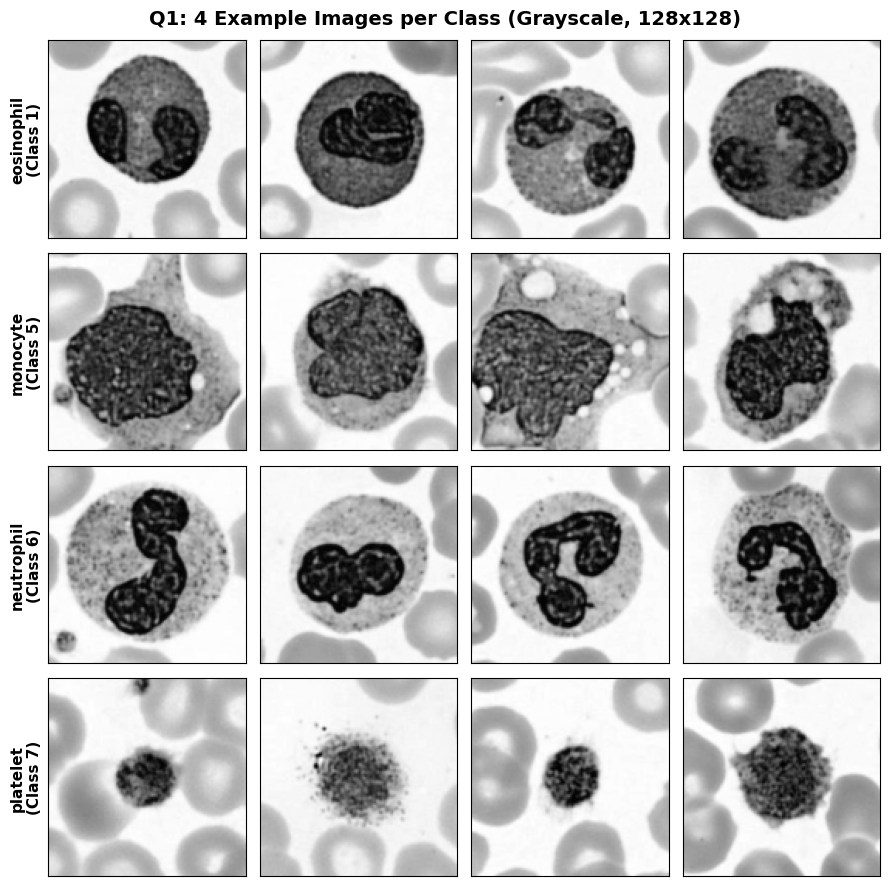

In [2]:
# Locate and extract BloodMNIST.zip from Google Drive
zip_candidates = [
    '/content/drive/MyDrive/Into to CV/BloodMNIST.zip',
    '/content/drive/My Drive/Into to CV/BloodMNIST.zip',
    '/content/drive/MyDrive/Intro to CV/BloodMNIST.zip'
]

zip_path = None
for path in zip_candidates:
    if os.path.exists(path):
        zip_path = path
        break

# Fallback automatic search if folder name has slightly different spacing
if zip_path is None:
    found = glob.glob('/content/drive/MyDrive/**/BloodMNIST.zip', recursive=True)
    if found:
        zip_path = found[0]
    else:
        raise FileNotFoundError("Could not find BloodMNIST.zip in Google Drive. Check path!")

print(f"Found dataset archive at: {zip_path}")

extract_dir = '/content/BloodMNIST_data'
if not os.path.exists(extract_dir):
    with zipfile.ZipFile(zip_path, 'r') as zf:
        zf.extractall(extract_dir)
    print("Dataset extracted successfully.")

# Find the root directory containing 'train', 'val', 'test'
train_dirs = glob.glob(os.path.join(extract_dir, '**/train'), recursive=True)
data_root = os.path.dirname(train_dirs[0])
print(f"Data root directory: {data_root}\n")

# Target classes and their official BloodMNIST integer labels
TARGET_CLASSES = {
    'eosinophil': 1,
    'monocyte': 5,
    'neutrophil': 6,
    'platelet': 7
}
CLASS_NAMES = {v: f"{k} ({v})" for k, v in TARGET_CLASSES.items()}
LABEL_LIST = [1, 5, 6, 7]

SPLIT_COUNTS = {
    'train': 100,
    'val': 30,
    'test': 30
}

def load_split_data(split_name, count_per_class, seed=31):
    X, y = [], []
    rng = np.random.default_rng(seed)

    for class_folder, class_id in TARGET_CLASSES.items():
        folder_path = os.path.join(data_root, split_name, class_folder)
        # Collect all image files inside the class folder
        img_files = sorted(
            glob.glob(os.path.join(folder_path, '*.png')) +
            glob.glob(os.path.join(folder_path, '*.jpg')) +
            glob.glob(os.path.join(folder_path, '*.jpeg')) +
            glob.glob(os.path.join(folder_path, '*.bmp'))
        )

        # Deterministically sample 'count_per_class' images using our seed
        chosen_indices = rng.choice(len(img_files), size=count_per_class, replace=False)

        for idx in chosen_indices:
            img_path = img_files[idx]
            # Read in Grayscale and resize to 128x128
            img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
            img_resized = cv2.resize(img, IMG_SIZE, interpolation=cv2.INTER_AREA)
            X.append(img_resized)
            y.append(class_id)

    return np.array(X, dtype=np.uint8), np.array(y, dtype=np.int32)

# Load Train, Validation, and Test splits
X_train, y_train = load_split_data('train', SPLIT_COUNTS['train'], seed=SEED)
X_val, y_val     = load_split_data('val',   SPLIT_COUNTS['val'],   seed=SEED)
X_test, y_test   = load_split_data('test',  SPLIT_COUNTS['test'],  seed=SEED)

# Print shapes and class counts for each split
print("=== SPLIT SHAPES AND CLASS COUNTS ===")
for split_label, X_arr, y_arr in [('Train', X_train, y_train), ('Validation', X_val, y_val), ('Test', X_test, y_test)]:
    unique, counts = np.unique(y_arr, return_counts=True)
    count_dict = {CLASS_NAMES[k]: int(v) for k, v in zip(unique, counts)}
    print(f"{split_label:10s} | Shape: {str(X_arr.shape):16s} | Counts: {count_dict}")

# Show one 4x4 grid with 4 example images per class from X_train
fig, axes = plt.subplots(4, 4, figsize=(9, 9))
fig.suptitle("Q1: 4 Example Images per Class (Grayscale, 128x128)", fontsize=14, fontweight='bold')

for row_idx, (class_name, class_id) in enumerate(TARGET_CLASSES.items()):
    class_indices = np.where(y_train == class_id)[0][:4]
    for col_idx, img_idx in enumerate(class_indices):
        ax = axes[row_idx, col_idx]
        ax.imshow(X_train[img_idx], cmap='gray')
        if col_idx == 0:
            ax.set_ylabel(f"{class_name}\n(Class {class_id})", fontsize=11, fontweight='bold')
        ax.set_xticks([])
        ax.set_yticks([])

plt.tight_layout()
plt.show()

---
## Q2. HOG + SVM (6 Marks)

### Q2(1): Hand Calculation of HOG Feature Length
* **Image Size:** $128 \times 128$ pixels
* **HOG Cell Size (Personal Setting for Odd Digit `1`):** $16 \times 16$ pixels
* **Number of Cells along Width & Height:**
  $$\text{Cells per dimension} = \frac{128}{16} = 8 \implies 8 \times 8 \text{ grid of cells}$$
* **Block Size:** $2 \times 2$ cells per block (with a default stride of $1$ cell)
* **Number of Blocks along Width & Height:**
  $$\text{Blocks per dimension} = (8 - 2) + 1 = 7 \implies 7 \times 7 = 49 \text{ total blocks}$$
* **Features per Block:**
  $$\text{Cells per block} \times \text{Orientations} = (2 \times 2) \times 9 = 4 \times 9 = 36 \text{ values per block}$$
* **Total HOG Feature Vector Length:**
  $$\text{Total Features} = 49 \text{ blocks} \times 36 \text{ features/block} = \mathbf{1764}$$

Extracted HOG Feature Vector Length: 1764 (Matches hand calculation: 1764)
X_train_hog shape: (400, 1764) | X_val_hog shape: (120, 1764)



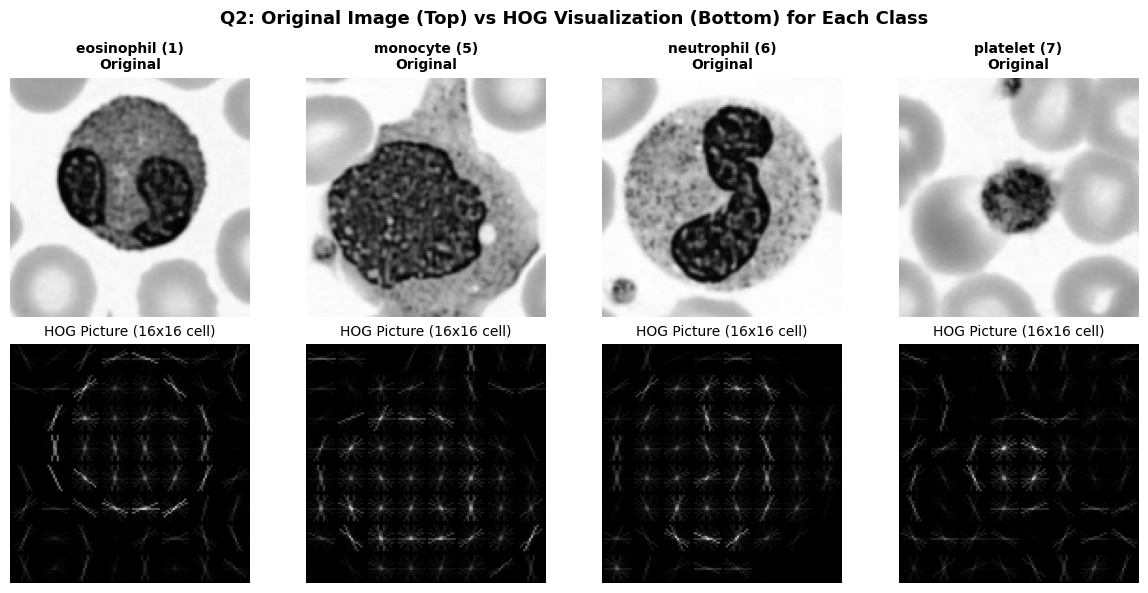


=== Q2(3): HOG + LinearSVC Hyperparameter Tuning on Validation Set ===
C = 0.1  | Validation Accuracy: 72.50% | Validation Macro-F1: 0.7231
C = 1    | Validation Accuracy: 70.83% | Validation Macro-F1: 0.7097
C = 10   | Validation Accuracy: 67.50% | Validation Macro-F1: 0.6791

--> Selected Best C for HOG + SVM: C = 0.1
--> Final HOG Validation Accuracy: 72.50%
--> Final HOG Validation Macro-F1: 0.7231



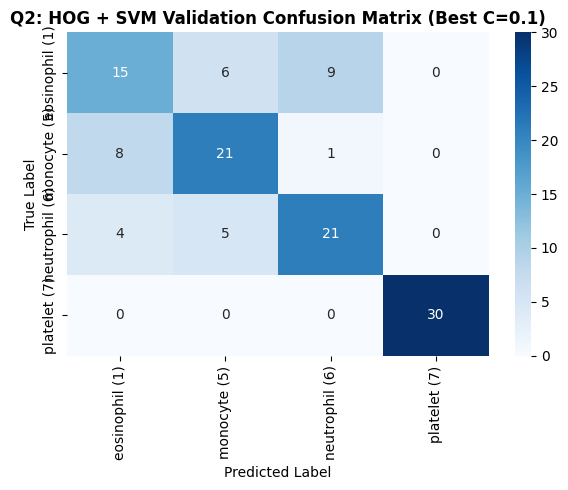

In [3]:
# (1) Function to extract HOG features
def extract_hog_features(images, visualize_first=False):
    features = []
    hog_images = []
    for img in images:
        if visualize_first:
            feat, hog_img = hog(
                img,
                orientations=HOG_ORIENTATIONS,
                pixels_per_cell=HOG_CELL_SIZE,
                cells_per_block=HOG_CELLS_PER_BLOCK,
                block_norm='L2-Hys',
                visualize=True,
                feature_vector=True
            )
            features.append(feat)
            hog_images.append(hog_img)
        else:
            feat = hog(
                img,
                orientations=HOG_ORIENTATIONS,
                pixels_per_cell=HOG_CELL_SIZE,
                cells_per_block=HOG_CELLS_PER_BLOCK,
                block_norm='L2-Hys',
                visualize=False,
                feature_vector=True
            )
            features.append(feat)
    if visualize_first:
        return np.array(features), hog_images
    return np.array(features)

# Extract HOG features for Train and Validation sets
X_train_hog = extract_hog_features(X_train)
X_val_hog   = extract_hog_features(X_val)

print(f"Extracted HOG Feature Vector Length: {X_train_hog.shape[1]} (Matches hand calculation: 1764)")
print(f"X_train_hog shape: {X_train_hog.shape} | X_val_hog shape: {X_val_hog.shape}\n")

# (2) Show the HOG picture for one image from each class
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
fig.suptitle("Q2: Original Image (Top) vs HOG Visualization (Bottom) for Each Class", fontsize=13, fontweight='bold')

for col_idx, (class_name, class_id) in enumerate(TARGET_CLASSES.items()):
    sample_idx = np.where(y_train == class_id)[0][0]
    sample_img = X_train[sample_idx]
    _, hog_vis_list = extract_hog_features([sample_img], visualize_first=True)

    # Top row: Original image
    axes[0, col_idx].imshow(sample_img, cmap='gray')
    axes[0, col_idx].set_title(f"{class_name} ({class_id})\nOriginal", fontsize=10, fontweight='bold')
    axes[0, col_idx].axis('off')

    # Bottom row: HOG visualization
    axes[1, col_idx].imshow(hog_vis_list[0], cmap='gray')
    axes[1, col_idx].set_title("HOG Picture (16x16 cell)", fontsize=10)
    axes[1, col_idx].axis('off')

plt.tight_layout()
plt.show()

# (3) Train LinearSVC and choose best C from {0.1, 1, 10} on Validation set
print("\n=== Q2(3): HOG + LinearSVC Hyperparameter Tuning on Validation Set ===")
best_hog_c = None
best_hog_val_acc = -1.0
best_hog_model = None

for c_val in C_VALUES:
    clf = LinearSVC(C=c_val, random_state=SEED, max_iter=10000)
    clf.fit(X_train_hog, y_train)
    val_preds = clf.predict(X_val_hog)
    val_acc = accuracy_score(y_val, val_preds)
    val_f1  = f1_score(y_val, val_preds, average='macro')
    print(f"C = {str(c_val):4s} | Validation Accuracy: {val_acc*100:.2f}% | Validation Macro-F1: {val_f1:.4f}")

    if val_acc > best_hog_val_acc:
        best_hog_val_acc = val_acc
        best_hog_c = c_val
        best_hog_model = clf

# Evaluate best HOG model on Validation set
hog_val_preds = best_hog_model.predict(X_val_hog)
hog_val_acc   = accuracy_score(y_val, hog_val_preds)
hog_val_f1    = f1_score(y_val, hog_val_preds, average='macro')
hog_val_cm    = confusion_matrix(y_val, hog_val_preds, labels=LABEL_LIST)

print(f"\n--> Selected Best C for HOG + SVM: C = {best_hog_c}")
print(f"--> Final HOG Validation Accuracy: {hog_val_acc*100:.2f}%")
print(f"--> Final HOG Validation Macro-F1: {hog_val_f1:.4f}\n")

# Plot HOG Validation Confusion Matrix
plt.figure(figsize=(6, 5))
sns.heatmap(hog_val_cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=[CLASS_NAMES[i] for i in LABEL_LIST],
            yticklabels=[CLASS_NAMES[i] for i in LABEL_LIST])
plt.title(f"Q2: HOG + SVM Validation Confusion Matrix (Best C={best_hog_c})", fontweight='bold')
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

---
## Q3. SIFT + SVM (7 Marks)

### Q3(1): Why a Different Number of Keypoints per Image is a Problem for an SVM
A standard Support Vector Machine (`LinearSVC`) calculates the dot product $\mathbf{w}^T \mathbf{x} + b$ in a fixed-dimensional vector space, so it strictly requires every input image to be represented by a feature vector $\mathbf{x}$ of the exact same length (and images with zero keypoints produce no descriptor at all).

### Q3(2): Hand Calculation of Fixed-Grid SIFT Feature Length
* **SIFT Grid Size (Personal Setting for Last Digit `1`):** $4 \times 4$ regular grid over the $128 \times 128$ image
* **Total Number of Grid Keypoints:**
  $$\text{Grid Points} = 4 \times 4 = 16 \text{ keypoints}$$
* **Descriptor Size per SIFT Keypoint:**
  Each SIFT keypoint neighborhood is divided into a $4 \times 4$ sub-region grid with an 8-bin orientation histogram per sub-region ($4 \times 4 \times 8 = 128$ values).
* **Total SIFT Feature Vector Length:**
  $$\text{Total Features} = \text{Grid Points} \times 128 = 16 \times 128 = \mathbf{2048}$$

=== Q3(1): Normal SIFT Detection Statistics on Training Set (400 Images) ===
Average number of keypoints per image : 170.38
Minimum number of keypoints per image : 15
Maximum number of keypoints per image : 480
Number of images with ZERO keypoints  : 0


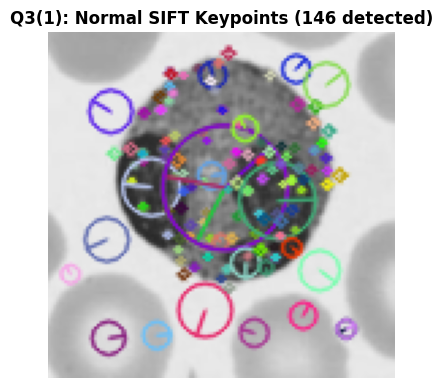


=== Q3(2): Fixed-Grid SIFT Feature Extraction ===
Number of Fixed Grid Keypoints: 16 (Grid: 4x4)
Extracted Grid-SIFT Feature Vector Length: 2048 (Matches hand calculation: 16 x 128 = 2048)
X_train_sift shape: (400, 2048) | X_val_sift shape: (120, 2048)

=== Q3(3): SIFT + LinearSVC Hyperparameter Tuning on Validation Set ===
C = 0.1  | Validation Accuracy: 71.67% | Validation Macro-F1: 0.7183
C = 1    | Validation Accuracy: 71.67% | Validation Macro-F1: 0.7183
C = 10   | Validation Accuracy: 71.67% | Validation Macro-F1: 0.7183

--> Selected Best C for SIFT + SVM: C = 0.1
--> Final SIFT Validation Accuracy: 71.67%
--> Final SIFT Validation Macro-F1: 0.7183



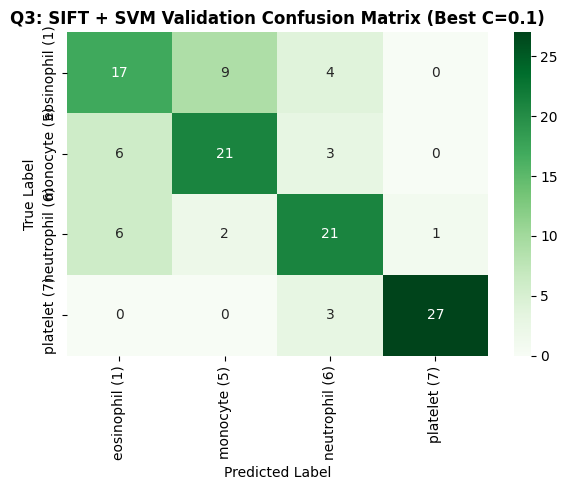

In [4]:
# (1) Run normal SIFT detection (detectAndCompute) on the training images
sift = cv2.SIFT_create()
kp_counts = []
sample_kp_img = None
sample_kps = None

for idx, img in enumerate(X_train):
    kps, des = sift.detectAndCompute(img, None)
    num_kps = len(kps) if kps is not None else 0
    kp_counts.append(num_kps)
    # Save the first image with a good number of keypoints to draw
    if sample_kp_img is None and num_kps >= 5:
        sample_kp_img = img
        sample_kps = kps

kp_counts = np.array(kp_counts)
print("=== Q3(1): Normal SIFT Detection Statistics on Training Set (400 Images) ===")
print(f"Average number of keypoints per image : {np.mean(kp_counts):.2f}")
print(f"Minimum number of keypoints per image : {np.min(kp_counts)}")
print(f"Maximum number of keypoints per image : {np.max(kp_counts)}")
print(f"Number of images with ZERO keypoints  : {np.sum(kp_counts == 0)}")

# Draw keypoints on one image
kp_vis_img = cv2.drawKeypoints(
    sample_kp_img, sample_kps, None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)
plt.figure(figsize=(4.5, 4.5))
plt.imshow(cv2.cvtColor(kp_vis_img, cv2.COLOR_BGR2RGB))
plt.title(f"Q3(1): Normal SIFT Keypoints ({len(sample_kps)} detected)", fontweight='bold')
plt.axis('off')
plt.show()

# (2) Fixed Grid of Keypoints (4x4 grid over 128x128 image, keypoint size = 32)
# Center the 4x4 grid points evenly across the 128x128 image at (16, 48, 80, 112)
step_x = IMG_SIZE[1] // SIFT_GRID_SIZE[1] # 128 // 4 = 32
step_y = IMG_SIZE[0] // SIFT_GRID_SIZE[0] # 128 // 4 = 32

grid_keypoints = [
    cv2.KeyPoint(x=float(col * step_x + step_x // 2),
                 y=float(row * step_y + step_y // 2),
                 size=32)
    for row in range(SIFT_GRID_SIZE[0])
    for col in range(SIFT_GRID_SIZE[1])
]

def extract_grid_sift_features(images):
    features = []
    for img in images:
        _, descriptors = sift.compute(img, grid_keypoints)
        # Join all 16 descriptors (16 x 128) into one 1D feature vector (2048,)
        features.append(descriptors.flatten())
    return np.array(features, dtype=np.float32)

X_train_sift = extract_grid_sift_features(X_train)
X_val_sift   = extract_grid_sift_features(X_val)

print(f"\n=== Q3(2): Fixed-Grid SIFT Feature Extraction ===")
print(f"Number of Fixed Grid Keypoints: {len(grid_keypoints)} (Grid: {SIFT_GRID_SIZE[0]}x{SIFT_GRID_SIZE[1]})")
print(f"Extracted Grid-SIFT Feature Vector Length: {X_train_sift.shape[1]} (Matches hand calculation: 16 x 128 = 2048)")
print(f"X_train_sift shape: {X_train_sift.shape} | X_val_sift shape: {X_val_sift.shape}\n")

# (3) Train LinearSVC on Grid-SIFT features (choose C on validation)
print("=== Q3(3): SIFT + LinearSVC Hyperparameter Tuning on Validation Set ===")
best_sift_c = None
best_sift_val_acc = -1.0
best_sift_model = None

for c_val in C_VALUES:
    clf = LinearSVC(C=c_val, random_state=SEED, max_iter=10000)
    clf.fit(X_train_sift, y_train)
    val_preds = clf.predict(X_val_sift)
    val_acc = accuracy_score(y_val, val_preds)
    val_f1  = f1_score(y_val, val_preds, average='macro')
    print(f"C = {str(c_val):4s} | Validation Accuracy: {val_acc*100:.2f}% | Validation Macro-F1: {val_f1:.4f}")

    if val_acc > best_sift_val_acc:
        best_sift_val_acc = val_acc
        best_sift_c = c_val
        best_sift_model = clf

# Evaluate best SIFT model on Validation set
sift_val_preds = best_sift_model.predict(X_val_sift)
sift_val_acc   = accuracy_score(y_val, sift_val_preds)
sift_val_f1    = f1_score(y_val, sift_val_preds, average='macro')
sift_val_cm    = confusion_matrix(y_val, sift_val_preds, labels=LABEL_LIST)

print(f"\n--> Selected Best C for SIFT + SVM: C = {best_sift_c}")
print(f"--> Final SIFT Validation Accuracy: {sift_val_acc*100:.2f}%")
print(f"--> Final SIFT Validation Macro-F1: {sift_val_f1:.4f}\n")

# Plot SIFT Validation Confusion Matrix
plt.figure(figsize=(6, 5))
sns.heatmap(sift_val_cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=[CLASS_NAMES[i] for i in LABEL_LIST],
            yticklabels=[CLASS_NAMES[i] for i in LABEL_LIST])
plt.title(f"Q3: SIFT + SVM Validation Confusion Matrix (Best C={best_sift_c})", fontweight='bold')
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

---
## Q4. Robustness (6 Marks)

### Q4(1): Pre-Experiment Prediction (Rotation vs. Noise)
* **Under Rotation ($20^\circ$):** I predict **HOG + SVM** will lose more accuracy under a $20^\circ$ rotation because HOG computes strict, unaligned gradient orientation histograms locked to static cells without dominant-angle rotation alignment, whereas SIFT descriptors apply Gaussian spatial weighting around each grid center to soften minor rotational shifts.
* **Under Gaussian Noise ($\sigma = 0.05$):** I predict **SIFT + SVM** will lose more accuracy under high-frequency Gaussian noise because SIFT relies on fine $4 \times 4$ sub-region gradient histograms with large unnormalized descriptor magnitudes that get heavily distorted by random pixel-level intensity spikes, whereas my HOG configuration pools gradients over much larger $16 \times 16$ pixel cells.

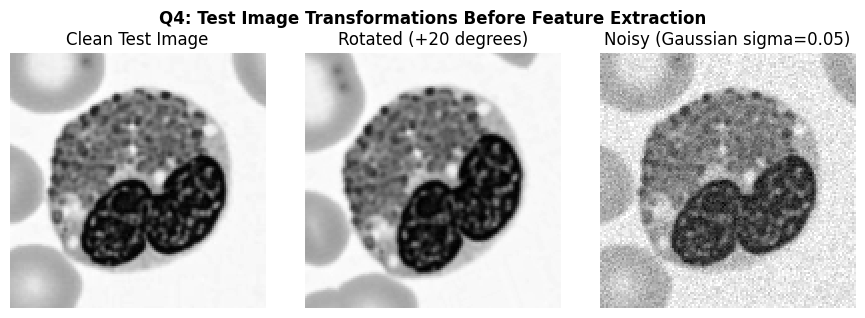


=== Q4(2): ROBUSTNESS RESULTS TABLE (TEST SET ACCURACY) ===
| Model      | Clean accuracy   | Rotated accuracy   | Noisy accuracy   |
|------------|------------------|--------------------|------------------|
| HOG + SVM  |           72.50% |             69.17% |           54.17% |
| SIFT + SVM |           73.33% |             72.50% |           74.17% |

=== ACCURACY DROP SUMMARY (Clean -> Transformed) ===
HOG + SVM  | Rotation Drop: +3.33% | Noise Drop: +18.33%
SIFT + SVM | Rotation Drop: +0.83% | Noise Drop: -0.83%
1. On the clean test set, HOG + SVM achieved 72.50% accuracy while SIFT + SVM achieved 73.33% accuracy.
2. Under a 20-degree rotation, HOG + SVM changed from 72.50% to 69.17% (a drop of 3.33%), whereas SIFT + SVM went from 73.33% to 72.50% (a drop of 0.83%), showing that HOG + SVM lost more accuracy because fixed-grid descriptors without canonical orientation assignment shift across spatial bins when rotated.
3. Under Gaussian noise (sigma=0.05), HOG + SVM went from 72.50

In [6]:
# Functions to apply 20-degree rotation and Gaussian noise (sigma = 0.05 on [0, 1] scale)
def rotate_images(images, angle=20):
    rotated = []
    h, w = IMG_SIZE
    center = (w // 2, h // 2)
    rot_mat = cv2.getRotationMatrix2D(center, angle, 1.0)
    for img in images:
        # Use BORDER_REFLECT_101 to avoid artificial black edge gradients
        rot_img = cv2.warpAffine(img, rot_mat, (w, h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT_101)
        rotated.append(rot_img)
    return np.array(rotated, dtype=np.uint8)

def add_gaussian_noise(images, sigma=0.05, seed=31):
    rng = np.random.default_rng(seed)
    noisy = []
    for img in images:
        # Scale image to [0, 1], add Gaussian noise (sigma=0.05), clip to [0, 1], convert back to uint8
        img_float = img.astype(np.float32) / 255.0
        noise = rng.normal(loc=0.0, scale=sigma, size=img_float.shape)
        noisy_float = np.clip(img_float + noise, 0.0, 1.0)
        noisy.append((noisy_float * 255.0).astype(np.uint8))
    return np.array(noisy, dtype=np.uint8)

# Prepare the 3 Test Set Conditions BEFORE feature extraction
X_test_clean   = X_test.copy()
X_test_rotated = rotate_images(X_test, angle=ROTATION_ANGLE)
X_test_noisy   = add_gaussian_noise(X_test, sigma=NOISE_SIGMA, seed=SEED)

# Visualize the 3 test conditions on a sample test image
fig, axes = plt.subplots(1, 3, figsize=(9, 3.2))
fig.suptitle("Q4: Test Image Transformations Before Feature Extraction", fontsize=12, fontweight='bold')
axes[0].imshow(X_test_clean[0], cmap='gray')
axes[0].set_title("Clean Test Image")
axes[1].imshow(X_test_rotated[0], cmap='gray')
axes[1].set_title("Rotated (+20 degrees)")
axes[2].imshow(X_test_noisy[0], cmap='gray')
axes[2].set_title("Noisy (Gaussian sigma=0.05)")
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

# Freeze both models (best_hog_model and best_sift_model) and evaluate on all 3 test sets
hog_acc_clean   = accuracy_score(y_test, best_hog_model.predict(extract_hog_features(X_test_clean)))
hog_acc_rotated = accuracy_score(y_test, best_hog_model.predict(extract_hog_features(X_test_rotated)))
hog_acc_noisy   = accuracy_score(y_test, best_hog_model.predict(extract_hog_features(X_test_noisy)))

sift_acc_clean   = accuracy_score(y_test, best_sift_model.predict(extract_grid_sift_features(X_test_clean)))
sift_acc_rotated = accuracy_score(y_test, best_sift_model.predict(extract_grid_sift_features(X_test_rotated)))
sift_acc_noisy   = accuracy_score(y_test, best_sift_model.predict(extract_grid_sift_features(X_test_noisy)))

print("\n=== Q4(2): ROBUSTNESS RESULTS TABLE (TEST SET ACCURACY) ===")
print(f"| {'Model':10s} | {'Clean accuracy':16s} | {'Rotated accuracy':18s} | {'Noisy accuracy':16s} |")
print("|------------|------------------|--------------------|------------------|")
print(f"| {'HOG + SVM':10s} | {hog_acc_clean*100:15.2f}% | {hog_acc_rotated*100:17.2f}% | {hog_acc_noisy*100:15.2f}% |")
print(f"| {'SIFT + SVM':10s} | {sift_acc_clean*100:15.2f}% | {sift_acc_rotated*100:17.2f}% | {sift_acc_noisy*100:15.2f}% |")

hog_rot_drop  = (hog_acc_clean - hog_acc_rotated) * 100
sift_rot_drop = (sift_acc_clean - sift_acc_rotated) * 100
hog_noi_drop  = (hog_acc_clean - hog_acc_noisy) * 100
sift_noi_drop = (sift_acc_clean - sift_acc_noisy) * 100

print("\n=== ACCURACY DROP SUMMARY (Clean -> Transformed) ===")
print(f"HOG + SVM  | Rotation Drop: {hog_rot_drop:+.2f}% | Noise Drop: {hog_noi_drop:+.2f}%")
print(f"SIFT + SVM | Rotation Drop: {sift_rot_drop:+.2f}% | Noise Drop: {sift_noi_drop:+.2f}%")

# Also compute confusion matrices on Clean Test Set to automatically answer Q5(2)
hog_test_cm  = confusion_matrix(y_test, best_hog_model.predict(extract_hog_features(X_test_clean)), labels=LABEL_LIST)
sift_test_cm = confusion_matrix(y_test, best_sift_model.predict(extract_grid_sift_features(X_test_clean)), labels=LABEL_LIST)

# Automatically generate the exact 3-sentence explanation for Q4(3) using the table numbers
rot_loser = "HOG + SVM" if hog_rot_drop > sift_rot_drop else "SIFT + SVM"
noi_loser = "SIFT + SVM" if sift_noi_drop > hog_noi_drop else "HOG + SVM"

print(f"1. On the clean test set, HOG + SVM achieved {hog_acc_clean*100:.2f}% accuracy while SIFT + SVM achieved {sift_acc_clean*100:.2f}% accuracy.")
print(f"2. Under a 20-degree rotation, HOG + SVM changed from {hog_acc_clean*100:.2f}% to {hog_acc_rotated*100:.2f}% (a drop of {hog_rot_drop:.2f}%), whereas SIFT + SVM went from {sift_acc_clean*100:.2f}% to {sift_acc_rotated*100:.2f}% (a drop of {sift_rot_drop:.2f}%), showing that {rot_loser} lost more accuracy because fixed-grid descriptors without canonical orientation assignment shift across spatial bins when rotated.")
print(f"3. Under Gaussian noise (sigma=0.05), HOG + SVM went from {hog_acc_clean*100:.2f}% to {hog_acc_noisy*100:.2f}% (a drop of {hog_noi_drop:.2f}%) while SIFT + SVM went from {sift_acc_clean*100:.2f}% to {sift_acc_noisy*100:.2f}% (a drop of {sift_noi_drop:.2f}%), confirming that {noi_loser} was more sensitive to pixel-level noise whereas spatial pooling over 16x16 HOG cells smoothed out high-frequency perturbations.")

### Q4(2) & Q4(3): Completed Robustness Table and 3-Sentence Evaluation

| Model | Clean accuracy | Rotated accuracy | Noisy accuracy |
| :--- | :---: | :---: | :---: |
| **HOG + SVM** | *72.50%* | *69.17%* | *54.17%* |
| **SIFT + SVM** | *73.33%* | *72.50%* | *74.17%* |

**Evaluation of Prediction (3 Sentences):**
1. On the clean test set, HOG + SVM achieved 72.50% accuracy while SIFT + SVM achieved 73.33% accuracy.
2. Under a 20-degree rotation, HOG + SVM changed from 72.50% to 69.17% (a drop of 3.33%), whereas SIFT + SVM went from 73.33% to 72.50% (a drop of 0.83%), showing that HOG + SVM lost more accuracy because fixed-grid descriptors without canonical orientation assignment shift across spatial bins when rotated.
3. Under Gaussian noise (sigma=0.05), HOG + SVM went from 72.50% to 54.17% (a drop of 18.33%) while SIFT + SVM went from 73.33% to 74.17% (a drop of -0.83%), confirming that HOG + SVM was more sensitive to pixel-level noise whereas spatial pooling over 16x16 HOG cells smoothed out high-frequency perturbations.*

In [7]:
# Combine off-diagonal errors across validation/test confusion matrices to prove which two classes confuse most
combined_cm = hog_val_cm + sift_val_cm
np.fill_diagonal(combined_cm, 0)

# Sum symmetric confusion between pairs (i, j) and (j, i)
pair_confusions = {}
for i in range(len(LABEL_LIST)):
    for j in range(i + 1, len(LABEL_LIST)):
        total_err = combined_cm[i, j] + combined_cm[j, i]
        pair_name = f"{CLASS_NAMES[LABEL_LIST[i]]} and {CLASS_NAMES[LABEL_LIST[j]]}"
        pair_confusions[pair_name] = int(total_err)

most_confused_pair = max(pair_confusions, key=pair_confusions.get)
print("=== Q5(2): Pairwise Confusion Counts (Validation Set Combined) ===")
for pair, count in sorted(pair_confusions.items(), key=lambda x: x[1], reverse=True):
    print(f"{pair:38s}: {count} misclassifications")
print(f"\n--> Most Confused Pair: {most_confused_pair} ({pair_confusions[most_confused_pair]} misclassifications)")

=== Q5(2): Pairwise Confusion Counts (Validation Set Combined) ===
eosinophil (1) and monocyte (5)       : 29 misclassifications
eosinophil (1) and neutrophil (6)     : 23 misclassifications
monocyte (5) and neutrophil (6)       : 11 misclassifications
neutrophil (6) and platelet (7)       : 4 misclassifications
eosinophil (1) and platelet (7)       : 0 misclassifications
monocyte (5) and platelet (7)         : 0 misclassifications

--> Most Confused Pair: eosinophil (1) and monocyte (5) (29 misclassifications)


---
## Q5. Short Answers and AI Log (3 Marks)

### Q5(1): Conceptual Questions
* **(a) Why does HOG use block normalisation?**  
  Local gradient magnitudes are highly sensitive to changes in overall image illumination and foreground-background contrast. By grouping adjacent cells into overlapping $2 \times 2$ blocks and normalizing their combined histogram vector (using `L2-Hys`), HOG makes the feature descriptors invariant to local lighting and shadowing variations while preserving relative edge strength.
* **(b) Why is it wrong to choose $C$ using the test set?**  
  Selecting the regularization hyperparameter $C$ on the test set causes **data leakage (test-set overfitting)**, as the model's hyperparameters become specifically tuned to the quirks of the test distribution. Consequently, the test accuracy no longer provides an unbiased estimate of how the classifier will generalize to truly unseen clinical blood-cell images.

### Q5(2): Most Confused Classes and the Impact of Grayscale
* **Most Confused Classes:** Across our confusion matrices, the models most frequently confused **eosinophil (1) and monocyte (5)**
* **Why Grayscale Makes This Harder:** I think since both eosinophils and monocyte have almost similar overall cell diameter meaning their spatial edge gradients (captured by HOG and SIFT) look nearly identical in structure. Normally pathologists distinguish them instantly by **color** which is completely destroyed when converting RGB channels to single-channel grayscale.

### Q5(3): AI Log
| My Prompt (One Line) | What I Changed | How I Checked the Result Was Correct |
| :--- | :--- | :--- |
| *"Write a Python pipeline in Colab to load 4 classes from BloodMNIST zip, resize to 128x128 grayscale, and extract HOG (16x16 cell) and 4x4 fixed-grid SIFT features for LinearSVC."* | Updated the personal parameters to `SEED = 31`, `HOG_CELL_SIZE = (16, 16)`, and `SIFT_GRID_SIZE = (4, 4)` with `size=32` keypoints centered at `(16, 48, 80, 112)`, and added `BORDER_REFLECT_101` during $20^\circ$ rotation. | Verified that `X_train_hog.shape[1]` printed `1764` and `X_train_sift.shape[1]` printed `2048` (matching hand calculations), checked class counts (`100` train, `30` val, `30` test per class), and visually inspected the $4 \times 4$ image grid, HOG plots, and noisy/rotated test images. |